### **`Ejercicio Integrales`**
### **`Montecarlo Integrales Parcial Miércoles 2025-2`**

#### Integral

<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-2-IntegralMartes.png" hspace="10px" vspace="0px">

El objetivo es calcular el área que se encuentra delimitada por los límites rojos y en color azul claro y aplicar el cálculo proporcional de una integral escalada para calcular el valor del área elegida. Para el presente ejercicio se debe calcular usando Montecarlo integrales y definir el valor del área con una precisión aceptable y calcular la convergencia tanto del área como de la proporción. Definir la cantidad mínima de réplicas de acuerdo con el proceso de convergencia realizado para el área y la proporción, además explicar la elección de este valor. Sustentar su respuesta con gráficas de convergencia independientes para ambos componentes (área y proporción).

Las siguientes ecuaciones pueden ser de uso:

<h1>
$m=\frac{y_2-y_1}{x_2-x_1}$

<h1>
$y = mx+b$

<h1>
$y-y_1=(\frac{y_2-y_1}{x_2-x_1})(x-x_1 )$

In [ ]:
#Solucion
import random as rnd
# Paso 1: definir las ecuaciones de cada recta, definir limite superior e inferior para x y para y
def Ecuacion1(x):
    return 2*x + 10
def Ecuacion2(x):
    return -x + 10
def Ecuacion3(x):
    return x-10
def Ecuacion4(x):
    return -2*x + 50

replicas = 100
minimox = 0
minimoy = 0
maximox = 20
maximoy = 20

def Integral(replicas):
    #copiar y pegar con cuidado
    area = 20*20
    hit = 0
    xhit,yhit = [],[]
    xmiss, ymiss = [],[]
    for _ in range(replicas):
        _x = rnd.uniform(minimox,maximox) #voy a proyectar x para poderlo comparar con y
        _y = rnd.uniform(minimoy,maximoy) # este es mi valor independiente
        ec1 = Ecuacion1(_x)
        ec2 = Ecuacion2(_x)
        ec3 = Ecuacion3(_x)
        ec4 = Ecuacion4(_x)
        if (_y < ec1) and (_y < ec4) and (_y > ec2) and (_y > ec3):
            hit += 1
            xhit.append(_x)
            yhit.append(_y)
        else:
            xmiss.append(_x)
            ymiss.append(_y)
    proporcion = hit / replicas # siempre va a estar entre 0 y 1
    area = area * proporcion # siempre va aser menor al estimado por el area
    return area, proporcion, xhit, yhit, xmiss, ymiss



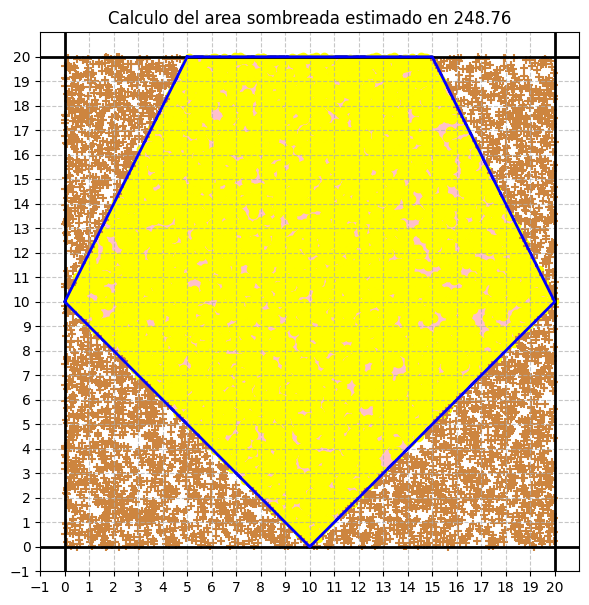

In [ ]:
# Prueba de la grafica, aciertos y desaciertos
area, proporcion, xhit, yhit, xmiss, ymiss = Integral(10000)
import matplotlib.pyplot as plt
x = [ 5,  0, 10, 15, 20, 15,  5]
y = [20, 10,  0,  5, 10, 20, 20]
plt.figure(figsize=(7, 7))
plt.fill(x, y, color='pink', edgecolor='black', linewidth=2)
plt.axvline(0, color='black', linewidth=2)
plt.axhline(0, color='black', linewidth=2)
plt.axvline(20, color='black', linewidth=2)
plt.axhline(20, color='black', linewidth=2)
plt.plot(x, y, color='blue', linewidth=2)
#aca debo poner los puntitos
plt.scatter(xhit, yhit, color = 'yellow', marker = 'o')
plt.scatter(xmiss, ymiss, color = 'peru', marker = '+')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-1, 21)
plt.ylim(-1, 21)
plt.xticks(range(-1, 21, 1))
plt.yticks(range(-1, 21, 1))
plt.gca().set_aspect('equal', adjustable='box')
plt.title(f'Calculo del area sombreada estimado en {area:,.2f}')
plt.show()

Calculando replicas...: 100%|██████████| 1000/1000 [00:01<00:00, 820.73it/s]


La convergencia inica en 14


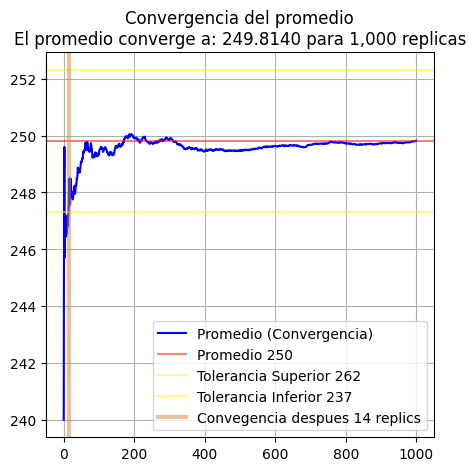

In [ ]:
# Calculo de Convergencia lineal del area, siempre entrega el mismo valor replics = 1000
import statistics as st
from tqdm import tqdm
replics = 1000
vEstimation = []
vMean = []
for i in tqdm(range(replics), 'Calculando replicas...'):
    vEstimation.append(Integral(replics)[0]) #siempre debe existir un tablero diferente
    vMean.append(st.mean(vEstimation))

vMeanR=vMean.copy()
vMeanR.reverse()
ts = vMean[-1]*1.01
ti = vMean[-1]*0.99
convergencia = 0
for j, k in enumerate(vMeanR):
    if k > ti and k < ts:
        pass
    else:
        convergencia = len(vMean)- j
        break
print(f'La convergencia inica en {convergencia}')
plt.figure(figsize=(5,5))
plt.plot(vMean, color='blue', label='Promedio (Convergencia)')
plt.axhline(vMean[-1], color='red', alpha=0.5, label=f'Promedio {vMean[-1]:,.0f}')
plt.axhline(vMean[-1]*1.01, color='yellow', alpha=0.5, label=f'Tolerancia Superior {vMean[-1]*1.05:,.0f}')
plt.axhline(vMean[-1]*0.99, color='yellow', alpha=0.5, label=f'Tolerancia Inferior {vMean[-1]*0.95:,.0f}')
plt.axvline(convergencia, color='peru', alpha=0.5,  linewidth=3 ,label=f'Convegencia despues {convergencia} replics')
plt.grid(True)
plt.title(f'Convergencia del promedio\nEl promedio converge a: {vMean[-1]:,.4f} para {replics:,} replicas')
plt.legend()
plt.show()

Calculando replicas...: 100%|██████████| 1000/1000 [00:01<00:00, 813.70it/s]


La convergencia inica en 0


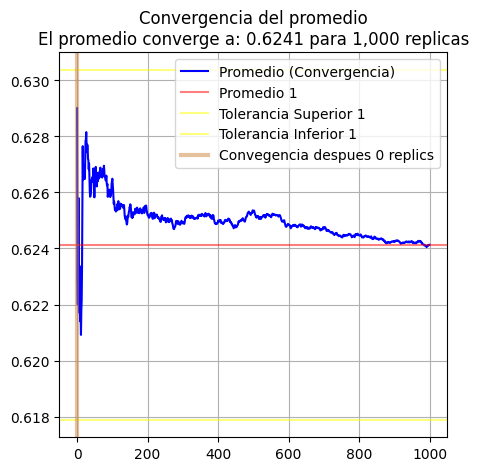

In [ ]:
# Calculo de Convergencia lineal del la proporcion, siempre entrega el mismo valor replics = 1000
import statistics as st
from tqdm import tqdm
replics = 1000
vEstimation = []
vMean = []
for i in tqdm(range(replics), 'Calculando replicas...'):
    vEstimation.append(Integral(replics)[1]) #siempre debe existir un tablero diferente
    vMean.append(st.mean(vEstimation))

vMeanR=vMean.copy()
vMeanR.reverse()
ts = vMean[-1]*1.01
ti = vMean[-1]*0.99
convergencia = 0
for j, k in enumerate(vMeanR):
    if k > ti and k < ts:
        pass
    else:
        convergencia = len(vMean)- j
        break
print(f'La convergencia inica en {convergencia}')
plt.figure(figsize=(5,5))
plt.plot(vMean, color='blue', label='Promedio (Convergencia)')
plt.axhline(vMean[-1], color='red', alpha=0.5, label=f'Promedio {vMean[-1]:,.0f}')
plt.axhline(vMean[-1]*1.01, color='yellow', alpha=0.5, label=f'Tolerancia Superior {vMean[-1]*1.05:,.0f}')
plt.axhline(vMean[-1]*0.99, color='yellow', alpha=0.5, label=f'Tolerancia Inferior {vMean[-1]*0.95:,.0f}')
plt.axvline(convergencia, color='peru', alpha=0.5,  linewidth=3 ,label=f'Convegencia despues {convergencia} replics')
plt.grid(True)
plt.title(f'Convergencia del promedio\nEl promedio converge a: {vMean[-1]:,.4f} para {replics:,} replicas')
plt.legend()
plt.show()

### **`Ejercicio Partidos`**
### **`Montecarlo Parcial Martes 2025-1`**

#### Estimar Ganador La Liga 2025-2026

<img alt="SauronTabla" height="400px" src="https://preview.redd.it/final-standings-of-la-liga-2024-2025-v0-5d56jpxo003f1.jpeg?width=1080&crop=smart&auto=webp&s=e5afcbb71999d9b4bb1746af73b4bff05a223a1d" hspace="10px" vspace="0px">

Un grupo de estudiantes de la Universidad de Antioquia desea dar sus primeros pasos en simulación deportiva y tienen como tarea realizar un proceso de estimación del ganador de La Liga 25-26, usando los resultados de La Liga 24-25 como se muestra en la ilustración 1.

Este estimativo se realiza con los valores de los puntos resultantes del año previo, dando como resultado las probabilidades de ganar La Liga que se muestran en la ilustración 2, esta es la probabilidad de ganar la liga como un evento único, pero como sabemos, la liga está compuesta por 20 equipos y cada uno juega 38 partidos (en formato de todos contra todos, ida y vuelta).

Cada jornada incluye 10 partidos, y hay 38 jornadas en total para un gran total de 380 partidos. El torneo pasado, 283 partidos terminaron con un equipo ganando el partido y 97 terminaron en empate. El empate ocurrió el 25% de las veces la temporada pasada.

El presente modelo tiene como meta simular los 380 partidos de La Liga, evaluando las probabilidades de ganar el partido o empatarlo, tanto para el visitante como para el local. El modelo al tener probabilidades generales, como se muestran en la Ilustración 2, se debe hacer una transformación de estas probabilidades generales a probabilidades por eventos individuales. Este procedimiento tiene la siguiente estrategia:
*   Se debe calcular la probabilidad individual del equipo local de ganar el partido, esta se calcula dividiendo el valor individual por la suma de los dos equipos involucrados en el partido. Al equipo local se le adiciona un valor aleatorio entre 0 y 15% para representar la ventaja de jugar en casa. Posteriormente, la probabilidad del visitante se define como el complemento de la probabilidad ajustada del local, de modo que ambas sigan sumando uno.
*   Luego de obtener el valor de victoria del equipo local y del equipo visitante, ahora debemos incluir el empate en la estructura. La probabilidad de empate se calcula de acuerdo con la ecuación 1, teniendo en cuenta su probabilidad. La nueva probabilidad de empate se debe incluir en las probabilidades previas de local y visitante. Estos valores se actualizan usando las ecuaciones 2 y 3.

Ahora teniendo las probabilidades de victoria del local, victoria del visitante y de empate, se debe evaluar el comportamiento del partido evaluando estos valores y dando tres puntos al vencedor y en caso de empate un punto a cada uno.

*   Ecuación 1
><h1>$p(Empate)=\frac{(1-(pLocal^2+pVisitante^2 ))}{2}$

*   Ecuación 2
><h1>$pLocal=pLocal*\frac{(1-pEmpate)}{(pLocal+pVisitante)}$

*   Ecuación 3
><h1>$pVisitante=pVisitante*\frac{(1-pEmpate)}{(pLocal+pVisitante)}$

Luego de simular los 380 partidos se debe crear una estrategia para determinar el procedimiento de evaluar el ganador de La Liga y posteriormente establecer un proceso de persistencia para conocer la probabilidad de quien gana La Liga luego de 1000 réplicas.

Define e interpreta en un párrafo los resultados, cada estudiante debe realizar una interpretación.

Se solicita adicionalmente calcular la convergencia de los puntos promedio con los que se gana La Liga y mostrar una gráfica para evaluar este procedimiento con una precisión del 1%.

Nota: Se deben usar funciones para resolver el presente problema. No hacerlo conlleva penalización de un punto.

Reto Bonificación: A los últimos tres equipos de La Liga en puntaje pierden la categoría y pasan a segunda división. Estima los tres equipos a los cuales la probabilidad de perder la categoría es más alta (se puede entregar hasta la media noche del día del parcial)
Bonificación 0.5 (solo enviar mediante correo electrónico).

*   Nota 1: No se permite usar temas no tratados en clase.
*   Nota 2: Usar diccionarios, tiene una bonificación de 0.3.

<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-2-ProbabilidadesGanarLaLiga_ParcialMartes.png" hspace="10px" vspace="0px">

```python
equipos = [
    "Real Madrid", "Barcelona", "Girona",
    "Espanyol", "Getafe", "Elche",
    "Athletic Club", "Real Betis",
    "Atlético Madrid", "Alavés",
    "Real Oviedo", "Sevilla", "Osasuna",
    "Rayo Vallecano", "Celta Vigo",
    "Levante", "Real Sociedad", "Valencia",
    "Villarreal", "Mallorca"]
```

```python
probabilidades = {
    'Barcelona': 11.29,
    'Real Madrid': 7.90,
    'Atlético Madrid': 7.14,
    'Athletic Club': 6.56,
    'Villarreal': 6.56,
    'Real Betis': 5.60,
    'Celta Vigo': 5.12,
    'Rayo Vallecano': 4.84,
    'Osasuna': 4.84,
    'Mallorca': 4.45,
    'Real Sociedad': 4.26,
    'Valencia': 4.26,
    'Getafe': 3.88,
    'Espanyol': 3.88,
    'Alavés': 3.88,
    'Girona': 3.78,
    'Sevilla': 3.78,
    'Elche': 2.66,
    'Levante': 2.66,
'Real Oviedo': 2.66
}

```


In [ ]:
probabilidades = {
    'Barcelona': 11.29,
    'Real Madrid': 7.90,
    'Atlético Madrid': 7.14,
    'Athletic Club': 6.56,
    'Villarreal': 6.56,
    'Real Betis': 5.60,
    'Celta Vigo': 5.12,
    'Rayo Vallecano': 4.84,
    'Osasuna': 4.84,
    'Mallorca': 4.45,
    'Real Sociedad': 4.26,
    'Valencia': 4.26,
    'Getafe': 3.88,
    'Espanyol': 3.88,
    'Alavés': 3.88,
    'Girona': 3.78,
    'Sevilla': 3.78,
    'Elche': 2.66,
    'Levante': 2.66,
'Real Oviedo': 2.66
}
equipos = [
    "Real Madrid", "Barcelona", "Girona",
    "Espanyol", "Getafe", "Elche",
    "Athletic Club", "Real Betis",
    "Atlético Madrid", "Alavés",
    "Real Oviedo", "Sevilla", "Osasuna",
    "Rayo Vallecano", "Celta Vigo",
    "Levante", "Real Sociedad", "Valencia",
    "Villarreal", "Mallorca"]

In [ ]:
print(probabilidades['Barcelona'])

11.29


In [ ]:
def Probabilidades(local:str, visitante:str, prob:dict): #Recibe texto de local texto de visitante y probabilidades
    pLocal = prob[local]
    pVisitante = prob[visitante]
    total = pLocal + pVisitante
    prob_Local = pLocal/total
    prob_mas_local = rnd.uniform(0,0.15) # le da el valor adicional de local
    prob_Local += prob_mas_local
    prob_Visitante = 1 - prob_Local
    return prob_Local, prob_Visitante

def ProbabilidadEmpate(local:float, visitante:float): #Debo recibir las probabilidades
    empate = (1- (local**2 + visitante**2))
    empate = empate / 2
    return empate

def AjustarProbabilidades(p_local:float, p_visitante:float, p_empate):
    factor = 1 - p_empate
    p_local_ajustada = p_local * factor / (p_local + p_visitante) # Ajusta la probabilidad del local
    p_visitante_ajustada = p_visitante * factor / (p_local + p_visitante) # Ajusta la probabilidad del visitante
    return p_local_ajustada, p_visitante_ajustada, p_empate

def Partido(local:str, prob_local:float ,visitante:str, prob_visitante:float, prob_empate:float):
    # Esta función simula un único partido de fútbol entre dos equipos.
    # Recibe los nombres de los equipos local y visitante, y sus respectivas probabilidades
    # de ganar o empatar.

    # 1. Generar un número aleatorio:
    # Piensa en esto como lanzar un dado especial y ponderado. El resultado de este lanzamiento
    # determinará el resultado del partido basándose en las probabilidades.
    p = rnd.random()

    # 2. Determinar el resultado del partido:
    # Comparamos nuestro 'lanzamiento de dado' aleatorio (p) con las probabilidades dadas.

    # Si 'p' es menor que la probabilidad de victoria del equipo local:
    # Esto significa que el número aleatorio cayó en el rango donde gana el equipo local.
    if p < prob_local:
        return 'Ganador', local # ¡El equipo local gana!

    # Si 'p' NO es menor que prob_local, pero SÍ es menor que las probabilidades combinadas
    # de que gane el equipo local O el equipo visitante:
    # Esto significa que el número aleatorio cayó en el rango donde gana el equipo visitante.
    # Nota: prob_local + prob_visitante aquí representa la probabilidad total de que gane cualquiera de los dos equipos (sin empate).
    elif p < (prob_local + prob_visitante):
        return 'Ganador visitante', visitante # ¡El equipo visitante gana! He añadido 'visitante' aquí para devolver el nombre del equipo.

    # Si ninguna de las condiciones anteriores se cumple:
    # Esto significa que el número aleatorio cayó en el espacio de probabilidad restante, que es para un empate.
    else:
        return 'Empate', None # ¡El partido es un empate! (Devolvemos None para el ganador en caso de empate)

#Aca ya me puedo encargar del modelo, y lo primero que se debe hacer es la combinatoria

In [ ]:
#Combinatoria para todos los partidos
partidos = []
for local in equipos:
    for visitante in equipos:
        if local != visitante:
            partidos.append([local,visitante])
# funcion para decir quien es el ganador y quien es el perdedor
def Partidos(partidos, probEquipos): # probEquipos es el diccionario que nos entrego el ejercicio
    dicEquipos = {equipo:0 for equipo in equipos}
    #Debo recorrer todos los partidos
    for local, visitante in partidos:
        plocal,pvisitante = Probabilidades(local, visitante, probEquipos)
        pempate = ProbabilidadEmpate(plocal,pvisitante)
        plocal, pvisitante, pempate = AjustarProbabilidades(plocal, pvisitante, pempate)
        partido = Partido(local, plocal, visitante, pvisitante,pempate)
        if partido[0] == 'Ganador':
            dicEquipos[partido[1]] += 3
        else:
            dicEquipos[local] += 1
            dicEquipos[visitante] += 1
    return dicEquipos #Ya termino el modelo de simulacion




In [ ]:
print(Partidos(partidos,probabilidades))

{'Real Madrid': 53, 'Barcelona': 62, 'Girona': 45, 'Espanyol': 36, 'Getafe': 51, 'Elche': 34, 'Athletic Club': 53, 'Real Betis': 52, 'Atlético Madrid': 49, 'Alavés': 45, 'Real Oviedo': 39, 'Sevilla': 43, 'Osasuna': 42, 'Rayo Vallecano': 51, 'Celta Vigo': 44, 'Levante': 36, 'Real Sociedad': 43, 'Valencia': 41, 'Villarreal': 51, 'Mallorca': 55}


In [ ]:
def Ganador(dic:dict):
    llave_ganador = max(dic, key = dic.get)
    return llave_ganador, dic[llave_ganador]

replicas = 1000
dicEquipos = {equipo:0 for equipo in equipos}
for i in tqdm(range(replicas), 'Calculando....'):
    liga = Partidos(partidos, probabilidades)
    ganador = Ganador(liga)
    dicEquipos[ganador[0]]+=1
print()
print(dicEquipos)


Calculando....: 100%|██████████| 1000/1000 [00:00<00:00, 1901.51it/s]


{'Real Madrid': 169, 'Barcelona': 540, 'Girona': 4, 'Espanyol': 3, 'Getafe': 1, 'Elche': 0, 'Athletic Club': 58, 'Real Betis': 24, 'Atlético Madrid': 70, 'Alavés': 6, 'Real Oviedo': 1, 'Sevilla': 2, 'Osasuna': 11, 'Rayo Vallecano': 12, 'Celta Vigo': 21, 'Levante': 0, 'Real Sociedad': 10, 'Valencia': 9, 'Villarreal': 51, 'Mallorca': 8}


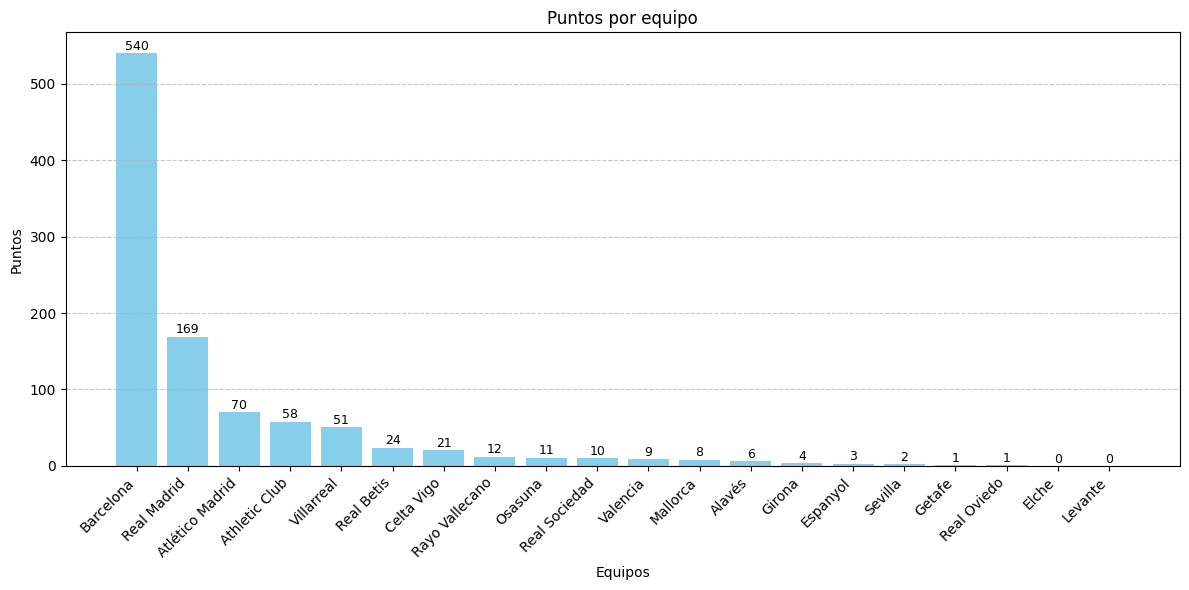

In [ ]:
dic_ordenado = dict(sorted(dicEquipos.items(), key = lambda x: x[1], reverse = True))
#Crear la grafica
plt.figure(figsize = (12,6))
barras = plt.bar(dic_ordenado.keys(), dic_ordenado.values(), color = 'skyblue')

#Agregar los valores encima de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width() / 2, altura + 0.5, str(altura), ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation =45, ha='right')
plt.title('Puntos por equipo')
plt.xlabel('Equipos')
plt.ylabel('Puntos')
plt.tight_layout()
plt.grid(axis = 'y', linestyle='--', alpha = 0.7)
plt.show()

### **`Ejercicio Integrales`**
### **`Montecarlo Integrales Parcial Martes 2025-2`**

#### Integral

<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-2-IntegralMiercoles.png" hspace="10px" vspace="0px">

El objetivo es calcular el área que se encuentra delimitada por los límites rojos y en color azul claro y aplicar el cálculo proporcional de una integral escalada para calcular el valor del área elegida. Para el presente ejercicio se debe calcular usando Montecarlo integrales y definir el valor del área con una precisión aceptable y calcular la convergencia tanto del área como de la proporción. Definir la cantidad mínima de réplicas de acuerdo con el proceso de convergencia realizado para el área y la proporción, además explicar la elección de este valor. Sustentar su respuesta con gráficas de convergencia independientes para ambos componentes (área y proporción).

Las siguientes ecuaciones pueden ser de uso:

<h1>
$m=\frac{y_2-y_1}{x_2-x_1}$

<h1>
$y = mx+b$

<h1>
$y-y_1=(\frac{y_2-y_1}{x_2-x_1})(x-x_1 )$

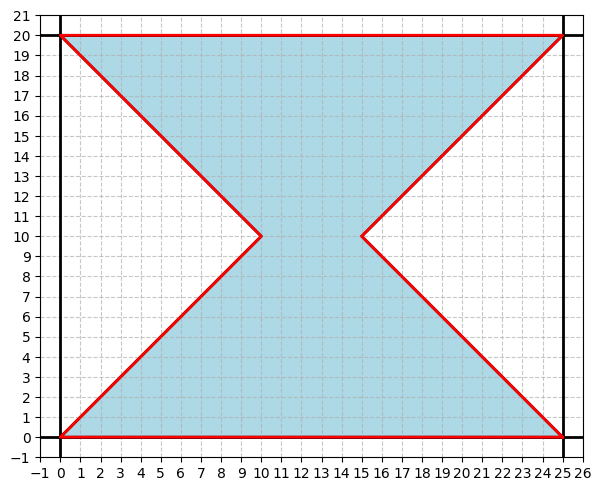

In [ ]:
import matplotlib.pyplot as plt
x = [25,  0,  10,  0,  25,  15, 25]
y = [ 0,  0,  10,  20,  20,  10,  0]
plt.figure(figsize=(7, 7))
plt.fill(x, y, color='lightblue', edgecolor='black', linewidth=2)
plt.axvline(0, color='black', linewidth=2)
plt.axhline(0, color='black', linewidth=2)
plt.axvline(25, color='black', linewidth=2)
plt.axhline(20, color='black', linewidth=2)
plt.plot(x, y, color='red', linewidth=2)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-1, 25)
plt.ylim(-1, 21)
plt.xticks(range(-1, 27, 1))
plt.yticks(range(-1, 22, 1))
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

In [ ]:
#Solución
#primer paso, hallar las ecuaciones de las rectas que necesito

def Ecuacion_1(x):
    return x
def Ecuacion_2(x):
    return -x+20
def Ecuacion_3(x):
    return x-5
def Ecuacion_4(x):
    return -x + 25
replicas =1000
minx = 0
maxx = 25
miny = 0
maxy = 20

def Integral2(replicas):
    area = 25*20
    hit = 0
    xhit,yhit = [],[]
    xmiss, ymiss = [],[]
    for _ in range(replicas):
        _x = rnd.uniform(minx,maxx) #voy a proyectar x para poderlo comparar con y
        _y = rnd.uniform(miny,maxy) # este es mi valor independiente
        ec1 = Ecuacion_1(_x)
        ec2 = Ecuacion_2(_x)
        ec3 = Ecuacion_3(_x)
        ec4 = Ecuacion_4(_x)
        if ((_y < ec1) and (_y < ec4)) or (_y > ec2) and (_y > ec3):
            hit += 1
            xhit.append(_x)
            yhit.append(_y)
        else:
            xmiss.append(_x)
            ymiss.append(_y)
    proporcion = hit / replicas # siempre va a estar entre 0 y 1
    area = area * proporcion # siempre va aser menor al estimado por el area
    return area, proporcion, xhit, yhit, xmiss, ymiss

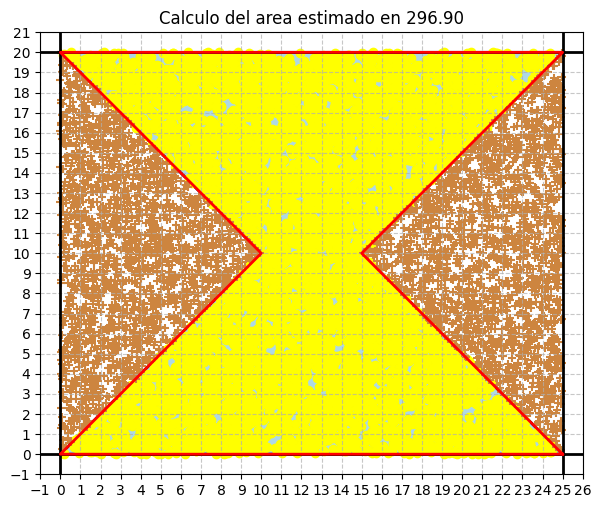

In [ ]:
# Prueba de la grafica, aciertos y desaciertos
area, proporcion, xhit, yhit, xmiss, ymiss = Integral2(10000)

import matplotlib.pyplot as plt
x = [25,  0,  10,  0,  25,  15, 25]
y = [ 0,  0,  10,  20,  20,  10,  0]
plt.figure(figsize=(7, 7))
plt.fill(x, y, color='lightblue', edgecolor='black', linewidth=2)
plt.axvline(0, color='black', linewidth=2)
plt.axhline(0, color='black', linewidth=2)
plt.axvline(25, color='black', linewidth=2)
plt.axhline(20, color='black', linewidth=2)
plt.plot(x, y, color='red', linewidth=2)
plt.scatter(xhit, yhit, color = 'yellow', marker = 'o')
plt.scatter(xmiss, ymiss, color = 'peru', marker = '+')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-1, 25)
plt.ylim(-1, 21)
plt.xticks(range(-1, 27, 1))
plt.yticks(range(-1, 22, 1))
plt.gca().set_aspect('equal', adjustable='box')
plt.title(f'Calculo del area estimado en {area:,.2f}')
plt.show()


Calculando replicas...: 100%|██████████| 1000/1000 [00:01<00:00, 570.35it/s]


La convergencia inica en 2


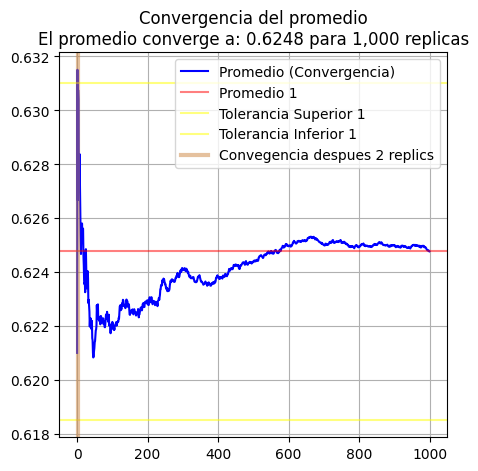

In [ ]:
# Calculo de Convergencia lineal de la proporcion, siempre entrega el mismo valor replics = 1000
import statistics as st
from tqdm import tqdm
replics = 1000
vEstimation = []
vMean = []
for i in tqdm(range(replics), 'Calculando replicas...'):
    vEstimation.append(Integral(replics)[1]) #siempre debe existir un tablero diferente
    vMean.append(st.mean(vEstimation))

vMeanR=vMean.copy()
vMeanR.reverse()
ts = vMean[-1]*1.01
ti = vMean[-1]*0.99
convergencia = 0
for j, k in enumerate(vMeanR):
    if k > ti and k < ts:
        pass
    else:
        convergencia = len(vMean)- j
        break
print(f'La convergencia inica en {convergencia}')
plt.figure(figsize=(5,5))
plt.plot(vMean, color='blue', label='Promedio (Convergencia)')
plt.axhline(vMean[-1], color='red', alpha=0.5, label=f'Promedio {vMean[-1]:,.0f}')
plt.axhline(vMean[-1]*1.01, color='yellow', alpha=0.5, label=f'Tolerancia Superior {vMean[-1]*1.05:,.0f}')
plt.axhline(vMean[-1]*0.99, color='yellow', alpha=0.5, label=f'Tolerancia Inferior {vMean[-1]*0.95:,.0f}')
plt.axvline(convergencia, color='peru', alpha=0.5,  linewidth=3 ,label=f'Convegencia despues {convergencia} replics')
plt.grid(True)
plt.title(f'Convergencia del promedio\nEl promedio converge a: {vMean[-1]:,.4f} para {replics:,} replicas')
plt.legend()
plt.show()

Calculando replicas...: 100%|██████████| 1000/1000 [00:01<00:00, 964.83it/s]


La convergencia inica en 22


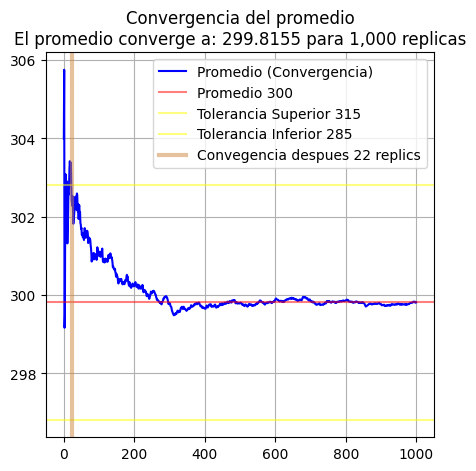

In [ ]:
# Calculo de Convergencia lineal del area, siempre entrega el mismo valor replics = 1000
import statistics as st
from tqdm import tqdm
replics = 1000
vEstimation = []
vMean = []
for i in tqdm(range(replics), 'Calculando replicas...'):
    vEstimation.append(Integral2(replics)[0]) #siempre debe existir un tablero diferente
    vMean.append(st.mean(vEstimation))

vMeanR=vMean.copy()
vMeanR.reverse()
ts = vMean[-1]*1.01
ti = vMean[-1]*0.99
convergencia = 0
for j, k in enumerate(vMeanR):
    if k > ti and k < ts:
        pass
    else:
        convergencia = len(vMean)- j
        break
print(f'La convergencia inica en {convergencia}')
plt.figure(figsize=(5,5))
plt.plot(vMean, color='blue', label='Promedio (Convergencia)')
plt.axhline(vMean[-1], color='red', alpha=0.5, label=f'Promedio {vMean[-1]:,.0f}')
plt.axhline(vMean[-1]*1.01, color='yellow', alpha=0.5, label=f'Tolerancia Superior {vMean[-1]*1.05:,.0f}')
plt.axhline(vMean[-1]*0.99, color='yellow', alpha=0.5, label=f'Tolerancia Inferior {vMean[-1]*0.95:,.0f}')
plt.axvline(convergencia, color='peru', alpha=0.5,  linewidth=3 ,label=f'Convegencia despues {convergencia} replics')
plt.grid(True)
plt.title(f'Convergencia del promedio\nEl promedio converge a: {vMean[-1]:,.4f} para {replics:,} replicas')
plt.legend()
plt.show()

### **`Ejercicio Parque norte`**
### **`Montecarlo Parcial Martes 2025-1`**

#### Ganancias Parque Norte

<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-2-ParqueNorte.png" hspace="10px" vspace="0px">

El Parque Norte (PN) de Medellín es un parque de atracciones emblemático de la ciudad, ubicado junto al Jardín Botánico y la Universidad de Antioquia. Cuenta con lagos, zonas verdes y una variedad de atracciones mecánicas y acuáticas para todas las edades. Es un lugar tradicional de encuentro, recreación y cultura para familias y visitantes.

Actualmente el PN quiere implementar una estrategia de descuentos que permita incentivar nuevas visitas al parque. Este proceso tiene en cuenta las visitas realizadas durante el año inmediatamente anterior. Para el año 2025 las visitas se estimaron para los días de atención (miércoles a domingo) en las siguientes:
*   Miércoles: entre 500 y 1500 personas
*   Jueves: entre 750 y 1800 personas
*   Viernes: entre 750 y 2500 personas
*   Sábado: entre 800 y 3000 personas
*   Domingo: entre 1000 y 4000 personas

El PN ofrece tres tipos de atracciones, Fantasía, Familiares y Extremas. Estas se abren al público todos los días y la población accede a ellas dependiendo en la mayoría de sus casos a la edad.

El PN tiene categorizada la población de acuerdo con los datos del año 2025. Estos datos determinan los siguientes criterios.

*   Entre 5 y 9 años solo visitan atracciones familiares. Es de anotar que los usuarios entre 5 y 9 años siempre están acompañados de un adulto.
*   Entre 10 y 17 años solo visitan atracciones de fantasía.
*   Entre 18 y 24 años solo visitan atracciones extremas
*   Entre 25 y 50 años visitan atracciones de fantasía y extremas
*   De 51 años en adelante visitan atracciones familiares.

En cuanto a los costos estos varían de acuerdo con el tipo de atracción así:
*   Fantasía: Los usuarios gastan entre 25000 y 83000
*   Extremas: Los usuarios gastan entre 15000 y 35000
*   Familiares: Los usuarios gastan entre 35000 y 53000

Ahora, en cuanto a los descuentos, el PN quiere implementar la siguiente estrategia.
*   Miércoles: 40% de descuento
*   Jueves: 30% de descuento
*   Viernes: 20% de descuento
*   Sábado: 10% de descuento
*   Domingo 0% de descuento

Con base en lo anterior, el PN desea saber el valor de ventas para el año 2026 con y sin descuento estimado con una precisión de al menos 100 repeticiones y una aceptación de un uno por ciento.

Adicional al comportamiento de los valores anualizados, el PN desea saber que pasaría si luego de mitad de año los días recibieran un incremento aleatorio de máximo el 15% diario. Como afectaría esto las ganancias con y sin descuentos.

Realiza las gráficas de convergencia para ambas estrategias y define en un párrafo si la estrategia de descuento es aplicable si el PN tiene unos gastos operacionales de $19.000.000.000.

Nota: Se deben usar funciones para resolver el presente problema. No hacerlo conlleva penalización de un punto.

Reto Bonificación: Crear una estrategia aleatoria de identificación de los usuarios y realizar una segregación adicional a los usuarios (se puede entregar hasta la media noche del día del parcial) Bonificación 0.5 (solo enviar mediante correo electrónico).

*   Nota 1: No se permite usar temas no tratados en clase.
*   Nota 2: Usar diccionarios, tiene una bonificación de 0.3.

Como funciona el match, case:  match busca en la variable que queremos analizar, si es el valor case da la instruccion.

In [ ]:
#Solucion
import random as rnd
# Miércoles: entre 500 y 1500 personas
# Jueves: entre 750 y 1800 personas
# Viernes: entre 750 y 2500 personas
# Sábado: entre 800 y 3000 personas
# Domingo: entre 1000 y 4000 personas


def Personas(dia:str):
    match dia:
        case 'Miércoles':
            return rnd.randint(500,1500)
        case 'Jueves':
            return rnd.randint(700,1800)
        case 'Viernes':
            return rnd.randint(750,2500)
        case 'Sabado':
            return rnd.randint(800,3000)
        case 'Domingo':
            return rnd.randint(1000,4000)
        case _:
            return 0

#identificar como es la edad, se puede hacer una propuesta

def Edad():
    p = rnd.random()
    if p > 0.75: # cada quien define los porcentajes, este es el primer 25%
        edad = rnd.randint(25,50)
        gasto = rnd.randint(25000,83000)
        gasto += rnd.randint(15000,35000)
    elif p > 0.5:
        edad = rnd.randint(10,17)
        gasto = rnd.randint(35000,53000)
    elif p > 0.35:
        edad = rnd.randint(18,24)
        gasto = rnd.randint(15000,35000)
    elif p > 0.25:
        edad = rnd.randint(5,9)
        gasto = rnd.randint(35000, 53000)
        gasto = gasto * 2
    else:
        edad = rnd.randint(51,99)
        gasto = rnd.randint(35000, 53000)
    return edad, gasto


def ParqueNorte():
    SEMANAS = 52
    dicDescuento = {'Miércoles': 0.6,
                    'Jueves': 0.7,
                    'Viernes': 0.8,
                    'Sabado': 0.9,
                    'Domingo': 1
    }
    dicGasto = {'Miércoles': [],
                'Jueves': [],
                'Viernes': [],
                'Sabado': [],
                'Domingo':[]
    }
    dicGastoSin = {'Miércoles': [],
                'Jueves': [],
                'Viernes': [],
                'Sabado': [],
                'Domingo':[]
    }
    for semana in range(SEMANAS):
        for dia in dicDescuento.keys():
            personas = Personas(dia)
            descuento = dicDescuento[dia]
            for personas in range(personas):
                edad, gasto = Edad()
                dicGastoSin[dia].append(gasto)
                gastod = int(gasto*descuento)
                dicGasto[dia].append(gastod)
    return dicGasto, dicGastoSin






In [ ]:
dicGasto, dicGastoSin = ParqueNorte()
def sumarDic(dic:dict):
    total = 0
    for llave in dic.keys():
        total += sum(dic[llave])
    return total

GastosSinDescuento = sumarDic(dicGastoSin)
GastosConDescuento = sumarDic(dicGasto)
print(f'${GastosSinDescuento:,.0f}')
print(f'${GastosConDescuento:,.0f}')

$23,685,425,575
$20,113,769,617


Calculo de Convergencia: 100%|██████████| 1000/1000 [09:28<00:00,  1.76it/s]


NameError: name 'replics' is not defined

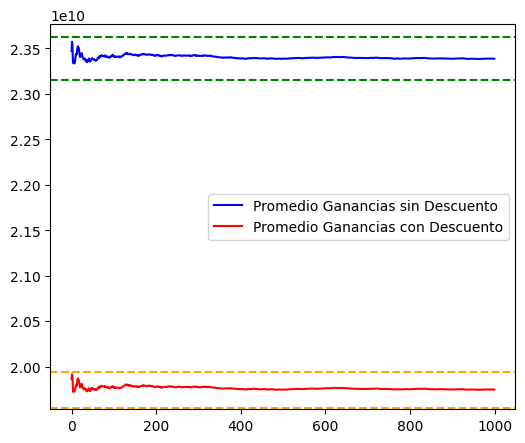

In [ ]:
import time
from statistics import mean
import matplotlib.pyplot as plt
from tqdm import tqdm

inicio = time.time()
vtemp_sin_desc = []
vtemp_con_desc = []
vpromedio_sin_desc = []
vpromedio_con_desc = []

for _ in tqdm(range(1000), desc='Calculo de Convergencia'):
    dicGasto, dicGastoSin = ParqueNorte()

    # Calculate the total sum of expenses for each simulation run
    total_gasto_sin_desc = sumarDic(dicGastoSin)
    total_gasto_con_desc = sumarDic(dicGasto)

    vtemp_sin_desc.append(total_gasto_sin_desc)
    vtemp_con_desc.append(total_gasto_con_desc)

    vpromedio_sin_desc.append(mean(vtemp_sin_desc))
    vpromedio_con_desc.append(mean(vtemp_con_desc))


plt.figure(figsize=(6,5))
plt.plot(vpromedio_sin_desc, color='blue', label='Promedio Ganancias sin Descuento')
plt.plot(vpromedio_con_desc, color='red', label='Promedio Ganancias con Descuento')


plt.axhline(vpromedio_sin_desc[-1]*1.01, color='green', linestyle='--')
plt.axhline(vpromedio_sin_desc[-1]*0.99, color='green', linestyle='--')
plt.axhline(vpromedio_con_desc[-1]*1.01, color='orange', linestyle='--')
plt.axhline(vpromedio_con_desc[-1]*0.99, color='orange', linestyle='--')

plt.legend()
plt.title(f'Convergencia de Ganancias Montecarlo ({replics} repeticiones)')
plt.xlabel('Iteraciones')
plt.ylabel('Ganancias')
plt.show()

fin = time.time()
print(f"Tiempo de ejecución: {fin - inicio:.2f} segundos")
print(f"Promedio ganancias sin descuento: {vpromedio_sin_desc[-1]:,.2f}")
print(f"Promedio ganancias con descuento: {vpromedio_con_desc[-1]:,.2f}")

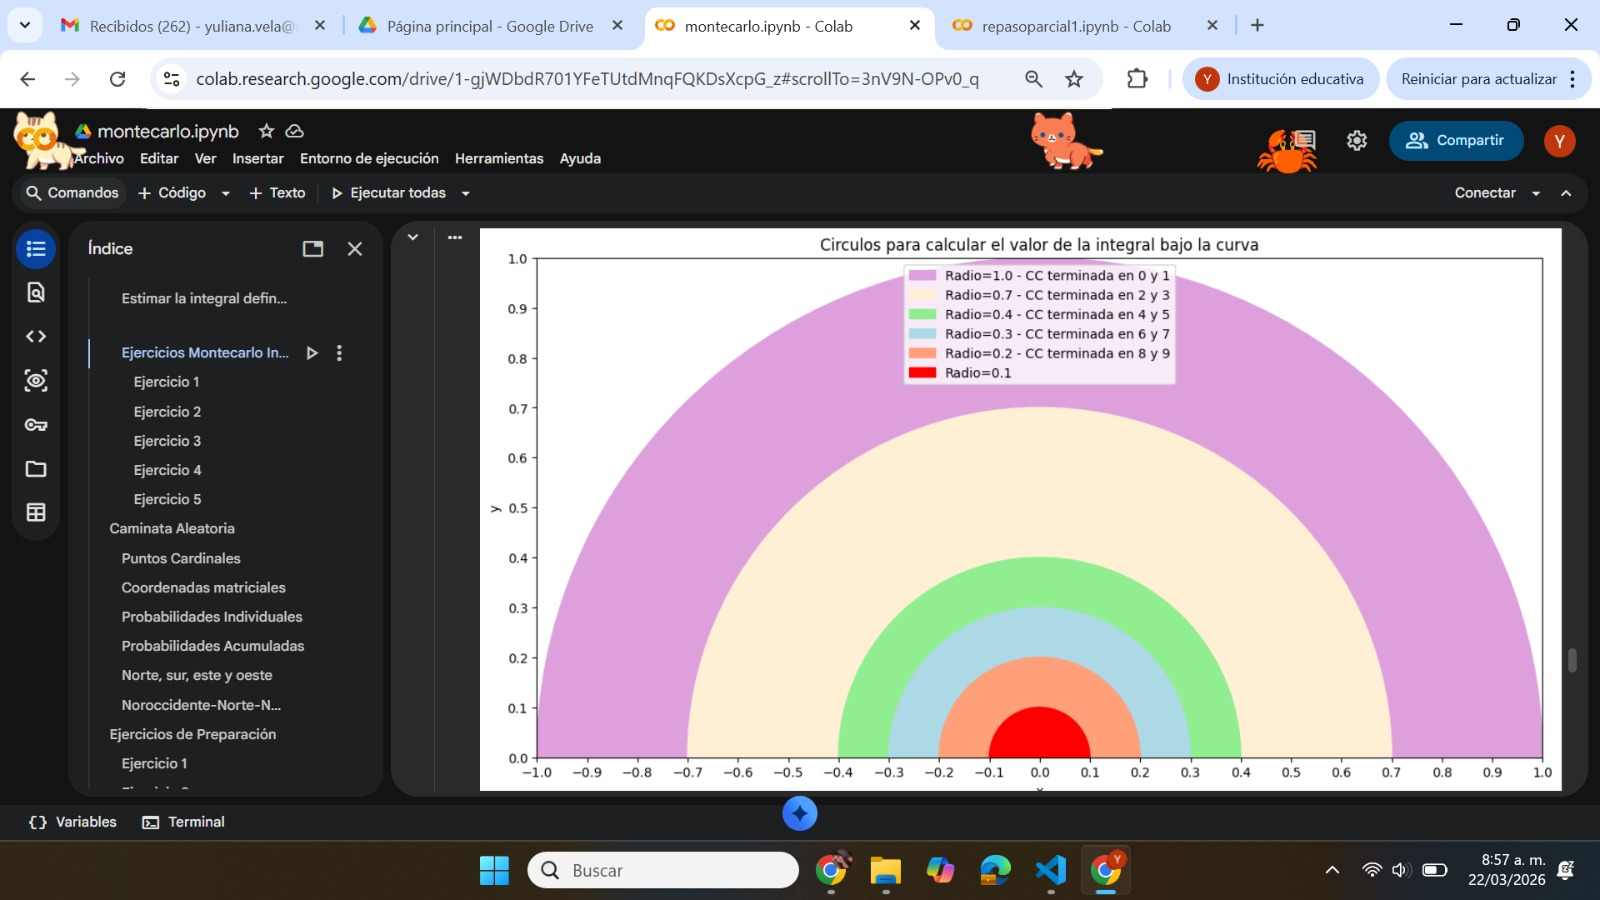

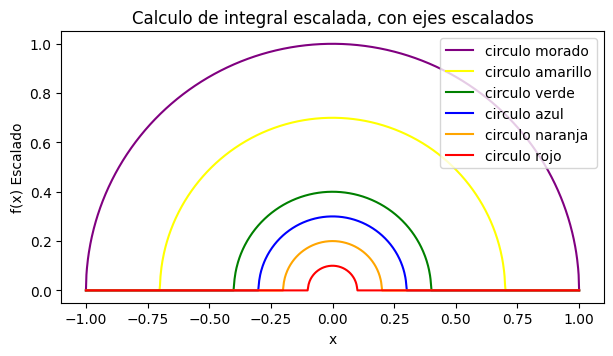

In [ ]:
#Graficar
import matplotlib.pyplot as plt
import numpy as np
#Grafica
import math as mt
#Código de las funciones
# Datos
x = np.linspace(-1, 1, 1000)
# circulo morado
circulomorado = np.sqrt(np.maximum(0, 1.0**2 - x**2))
# circulo amarillo
circuloamarillo = np.sqrt(np.maximum(0, 0.7**2 - x**2))
# circulo verde
circuloverde = np.sqrt(np.maximum(0, 0.4**2 - x**2))
# circulo azul
circuloazul = np.sqrt(np.maximum(0, 0.3**2 - x**2))
# circulo naranja
circulonaranja = np.sqrt(np.maximum(0, 0.2**2 - x**2))
# circulo rojo
circulorojo = np.sqrt(np.maximum(0, 0.1**2 - x**2))
# Gráficas
plt.figure(figsize=(7, 7))
plt.plot(x, circulomorado, color='purple', label='circulo morado')
plt.plot(x, circuloamarillo, color='yellow', label='circulo amarillo')
plt.plot(x, circuloverde, color='green', label='circulo verde')
plt.plot(x, circuloazul, color='blue', label='circulo azul')
plt.plot(x, circulonaranja, color='orange', label='circulo naranja')
plt.plot(x, circulorojo, color='red', label='circulo rojo')
plt.xlabel('x')
plt.axis('scaled')
plt.ylabel('f(x) Escalado')
plt.title('Calculo de integral escalada, con ejes escalados')
plt.legend()
plt.show()

In [ ]:
#Solucion
import random as rnd
# Paso 1: definir las ecuaciones de cada recta, definir limite superior e inferior para x y para y
def cic1(x):
    return np.sqrt(np.maximum(0, 1.0**2 - x**2)) #morado
def cic2(x):
    return np.sqrt(np.maximum(0, 0.7**2 - x**2)) #amarillo
def cic3(x):
    return np.sqrt(np.maximum(0, 0.4**2 - x**2)) #verde
def cic4(x):
    return np.sqrt(np.maximum(0, 0.3**2 - x**2)) #azul
def cic5(x):
    return np.sqrt(np.maximum(0, 0.2**2 - x**2)) #naranja
def cic6(x):
    return np.sqrt(np.maximum(0, 0.1**2 - x**2)) #rojo


replicas = 100
minimox = -1
minimoy = 0
maximox = 1
maximoy = 1

def Circulos(replicas):
    #copiar y pegar con cuidado
    area = 1*1
    hit = 0
    xhit,yhit = [],[]
    xmiss, ymiss = [],[]
    for _ in range(replicas):
        _x = rnd.uniform(minimox,maximox) #voy a proyectar x para poderlo comparar con y
        _y = rnd.uniform(minimoy,maximoy) # este es mi valor independiente
        ec1 = cic1(_x)
        ec2 = cic2(_x)
        ec3 = cic3(_x)
        ec4 = cic4(_x)
        ec5 = cic5(_x)
        ec6 = cic6(_x)
        #voy a pintar el area en azul
        if (_y < ec4) and (_y > ec5):
            hit += 1
            xhit.append(_x)
            yhit.append(_y)
        else:
            xmiss.append(_x)
            ymiss.append(_y)
    proporcion = hit / replicas # siempre va a estar entre 0 y 1
    area = area * proporcion # siempre va aser menor al estimado por el area
    return area, proporcion, xhit, yhit, xmiss, ymiss

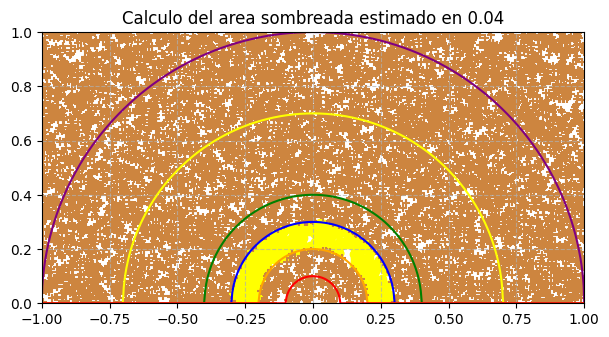

In [ ]:
# Prueba de la grafica, aciertos y desaciertos
area, proporcion, xhit, yhit, xmiss, ymiss = Circulos(10000)
import matplotlib.pyplot as plt
x = np.linspace(-1, 1, 1000)
# circulo morado
circulomorado = np.sqrt(np.maximum(0, 1.0**2 - x**2))
# circulo amarillo
circuloamarillo = np.sqrt(np.maximum(0, 0.7**2 - x**2))
# circulo verde
circuloverde = np.sqrt(np.maximum(0, 0.4**2 - x**2))
# circulo azul
circuloazul = np.sqrt(np.maximum(0, 0.3**2 - x**2))
# circulo naranja
circulonaranja = np.sqrt(np.maximum(0, 0.2**2 - x**2))
# circulo rojo
circulorojo = np.sqrt(np.maximum(0, 0.1**2 - x**2))
# Gráficas
plt.figure(figsize=(7, 7))
plt.plot(x, circulomorado, color='purple', label='circulo morado')
plt.plot(x, circuloamarillo, color='yellow', label='circulo amarillo')
plt.plot(x, circuloverde, color='green', label='circulo verde')
plt.plot(x, circuloazul, color='blue', label='circulo azul')
plt.plot(x, circulonaranja, color='orange', label='circulo naranja')
plt.plot(x, circulorojo, color='red', label='circulo rojo')
#aca debo poner los puntitos
plt.scatter(xhit, yhit, color = 'yellow', marker = 'o')
plt.scatter(xmiss, ymiss, color = 'peru', marker = '+')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-1, 1)
plt.ylim(0, 1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title(f'Calculo del area sombreada estimado en {area:,.2f}')
plt.show()

In [ ]:
#en caso de no estar centrado en cero asi seria la ecuacion
# circulo = k + np.sqrt(np.maximum(0, r**2 - (x - h)**2))
# donde h representa el punto en x y k en y

### **`Ejercicio 7`**
### **`Montecarlo Parcial Jueves 2025-1`**

#### Sauron vs La Última alianza de hombres  y elfos


<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-1-SauronEstudiando.png" hspace="10px" vspace="0px">


Sauron, un Maia corrompido que originalmente sirvió a Aulë antes de seguir a Morgoth, forjó el Anillo Único para dominar la Tierra Media, convirtiéndose en la encarnación del mal. Durante la Segunda Edad, la Guerra de la Última Alianza reunió a unos 60.000 Elfos y Hombres (55% Elfos y 45% Hombres estimadamente) liderados por Gil-galad y Elendil contra un ejército similar en número compuesto por Orcos, Trolls, hombres del este y del sur, y los Nazgûl. Aunque Sauron no combatió personalmente a todos, se estima que enfrentó entre el 10% y 15% de las fuerzas aliadas de forma secuencial. Su derrota final llegó cuando Isildur le cortó el Anillo Único de la mano, arrebatándole su poder físico y marcando el fin de su dominio, aunque su influencia persistió a través del Anillo.


Cada hombre y elfo tiene un poder de ataque o daño aleatorio uniforme, es decir, en un combate cuerpo a cuerpo cada uno de los participantes podría infligir un daño numérico entre un límite inferior y un límite superior, y asumiendo que Sauron derrota a todo enemigo al que se enfrenta y que solo el último combatiente de la alianza lo derrota. Podríamos establecer un modelo de simulación Montecarlo para estimar el poder (en números, acumulando) luego de evaluar su resistencia estocástica tras diferentes tipos de golpes.


Los hombres y los elfos que combatieron contra Sauron se dividieron en cinco clases para cada raza, y cada una tenía un porcentaje (probabilístico) de participación con respecto al total de la población y una capacidad uniforme de ataque de acuerdo con sus habilidades. Estos valores en conjunto con la cantidad, distribución, participación y daño se encuentran detallados en la ilustración 1.


Con base en lo anterior y sabiendo que el anillo único le otorga super poderes a Sauron, no solamente obtiene poderes físicos sino también mágicos, y esto le brinda un poder estocástico que anula cuatro de cada cinco ataques.


El objetivo del presente modelo es identificar cuántos ataques en promedio (convergencia) se necesitan para poder derrotar a Sauron y cuál es el daño promedio para poder derrotarlo (convergencia). También se desea conocer el promedio de daño infligido por Hombres y Elfos por separado. Favor realizar gráficas de convergencia para golpes fallidos, golpes aplicados y seleccionar la cantidad con la cual el modelo es estable (converge).

*   Nota 1: No se permite usar temas no tratados en clase.
*   Nota 2: Usar diccionarios, tiene una bonificación de 0.3.

<img alt="SauronTabla" height="400px" src="https://raw.githubusercontent.com/juliancastillo-udea/AlDiSi/refs/heads/main/images/2025-1-SauronTabla.png
" hspace="10px" vspace="0px">

Ilustración 1 - Detalle por Raza para la última alianza


In [ ]:
#Solucion

def Dano(raza:str):
    Raza = {
    'Arquero': 0.4,
    'Guerrero': 0.3,
    'Portador de magia': 0.1,
    'ArtesanoElfo': 0.15,
    'LiderElfo':0.05,
    'Elite': 0.5,
    'LiderHombre': 0.1,
    'Explorador': 0.15,
    'ArtesanoHombre': 0.10,
    'Sabio': 0.15
    }

    match raza:
        case 'Arquero':
            return rnd.randint(95,105)
        case 'Guerrero':
            return rnd.randint(125,153)
        case 'Portador de magia':
            return rnd.randint(175,201)
        case 'ArtesanoElfo':
            return rnd.randint(50,63)
        case 'LiderElfo':
            return rnd.randint(300,413)
        case 'Elite':
            return rnd.randint(100,123)
        case 'LiderHombre':
            return rnd.randint(150,177)
        case 'Explorador':
            return rnd.randint(90,109)
        case 'ArtesanoHombre':
            return rnd.randint(23,88)
        case 'Sabio':
            return rnd.randint(35,51)
        case _:
            return 0

def Probabilidad(diccionario):
    p = rnd.random()
    ptotal = 0
    for item, probabilidad in diccionario.items():
        ptotal += probabilidad
        if p <= ptotal:
            return item
    return list(distribution.keys())[-1]

def Pelea():
    aliados = {
        'Elfo': 0.55,
        'Hombre': 0.45
    }
    razas = {
        'Elfo': {
            'Arquero': 0.4,
            'Guerrero': 0.3,
            'Portador de magia': 0.1,
            'ArtesanoElfo': 0.15,
            'LiderElfo': 0.05
        },
        'Hombre': {
            'Elite': 0.5,
            'LiderHombre': 0.1,
            'Explorador': 0.15,
            'ArtesanoHombre': 0.10,
            'Sabio': 0.15 # Corrected based on image
        }
    }
    ejercito = 60000
    enfrentaSauron = 60000 * rnd.uniform(0.1,0.15)
    daño_total = 0
    golpes_fallidos = 0
    golpes_aplicados = 0

    for i in range(int(enfrentaSauron)):
        especie = Probabilidad(aliados)
        clase = Probabilidad(razas)
        daño = Dano(clase)
        if rnd.random() < 0.8:
            golpes_fallidos += 1
        else:
            daño_total += daño
            golpes_aplicados += 1
    return daño_total, golpes_fallidos, golpes_aplicados



**Metodos para diccionarios**

```
dic.get() #nos entrega los valores de alguna llave
dic.keys() #trae las llaves del diccionario
dic.values() # trae los valores del diccionario
dic.items() #trae todo, llaves con valores
dic.update() # agrega un valor nuevo al diccionario
dic.pop() #elimina un valor con su llave
dic.clear(): #elimina todos los elementos
```
 usando ciclo for
```
for key,value in dic.items():
    print(key,value)
```




**Libreria random**

```
import random as rnd
```

```
rnd.randrange(1,10,2) #genera numeros aleatorios enteros del 1 al 10 pares
rnd.uniform(1,10) #genera numeros continuos del 1 al 10
rnd.choice() # elige un elemento de una lista
rnd.sample(lista,2) # elige un cierto numero de elementos de una lista
rnd.random() # un numero flotante entre [0,1)
rnd.randint(a,b) #numero entero entre a y b incluyendolos
```





**Libreria numpy**

```
np.array() → crear arreglos
np.zeros(shape) → arreglo de ceros
np.ones(shape) → arreglo de unos
np.full(shape, value) → lleno con un valor
np.arange(start, stop, step) → rango tipo range
np.linspace(start, stop, num) → valores equiespaciados
```


```
import numpy as np

np.add(a, b)        # Suma elemento a elemento: suma cada valor de 'a' con el correspondiente de 'b'
a + b               # Hace exactamente lo mismo que np.add(a, b)

np.subtract(a, b)   # Resta elemento a elemento: a - b en cada posición

np.multiply(a, b)   # Multiplicación elemento a elemento (NO es producto matricial)

np.divide(a, b)     # División elemento a elemento: a / b

np.power(a, b)      # Eleva cada elemento de 'a' a la potencia correspondiente en 'b' (a^b)

np.sqrt(a)          # Raíz cuadrada de cada elemento de 'a'

np.exp(a)           # Calcula e^a para cada elemento (exponencial natural)

np.log(a)           # Logaritmo natural (base e) de cada elemento de 'a'
```



